In [2]:
import glob
print(glob.glob("q*.csv"))

[]


In [3]:
from pathlib import Path

home = Path.home()
names = ["q1_monthly_revenue.csv", "q2_categories.csv",
         "q2_states.csv", "q4_delay_vs_reviews.csv"]

for folder in ["Downloads", "Documents", "Desktop", "olist-project", "OneDrive"]:
    for name in names:
        for p in (home / folder).rglob(name):
            print(p)

C:\Users\Kramz\Downloads\archive\q1_monthly_revenue.csv
C:\Users\Kramz\Downloads\archive\q2_categories.csv
C:\Users\Kramz\Downloads\archive\q2_states.csv
C:\Users\Kramz\Downloads\archive\q4_delay_vs_reviews.csv


In [5]:
import pandas as pd
from pathlib import Path

folder = Path(r"C:\Users\Kramz\Downloads\archive")

q1 = pd.read_csv(folder / "q1_monthly_revenue.csv")
q2_cat = pd.read_csv(folder / "q2_categories.csv")
q2_state = pd.read_csv(folder / "q2_states.csv")
q4 = pd.read_csv(folder / "q4_delay_vs_reviews.csv")

print(q1.shape, q2_cat.shape, q2_state.shape, q4.shape)
q1.head()

(20, 5) (10, 5) (10, 4) (5, 3)


,month,orders,revenue,mom_growth_pct,running_total
0,2017-01,750,111798.36,NaN,111798.36
1,2017-02,1653,234223.40,109.5,346021.76
2,2017-03,2546,359198.85,53.4,705220.61
3,2017-04,2303,340669.68,-5.2,1045890.29
4,2017-05,3546,489338.25,43.6,1535228.54


Matplotlib is building the font cache; this may take a moment.


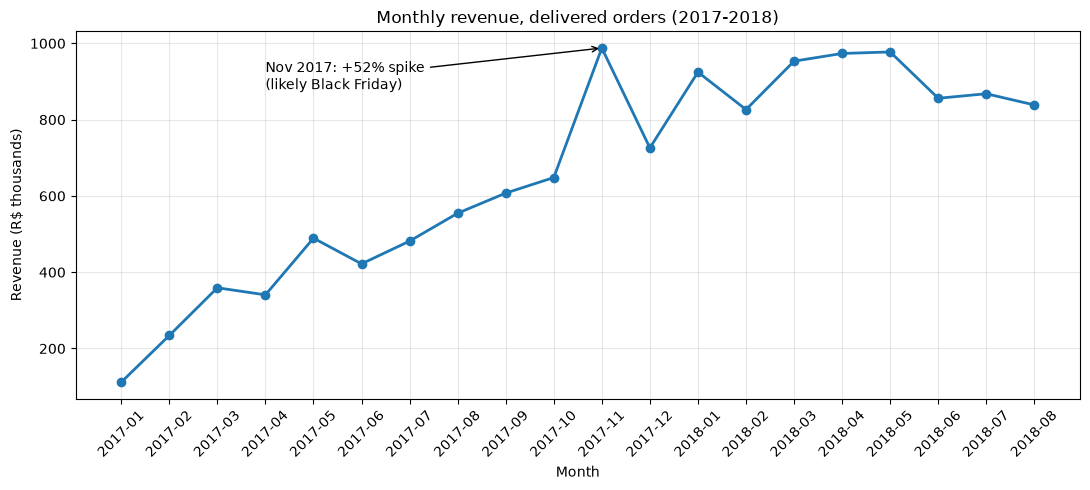

In [6]:
import matplotlib.pyplot as plt

images = folder / "images"
images.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(q1["month"], q1["revenue"] / 1000, marker="o", linewidth=2, color="#1f77b4")

peak = q1[q1["month"] == "2017-11"].iloc[0]
ax.annotate(
    "Nov 2017: +52% spike\n(likely Black Friday)",
    xy=("2017-11", peak["revenue"] / 1000),
    xytext=("2017-04", 880),
    arrowprops=dict(arrowstyle="->"),
)

ax.set_title("Monthly revenue, delivered orders (2017-2018)")
ax.set_ylabel("Revenue (R$ thousands)")
ax.set_xlabel("Month")
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(images / "q1_monthly_revenue.png", dpi=150)
plt.show()

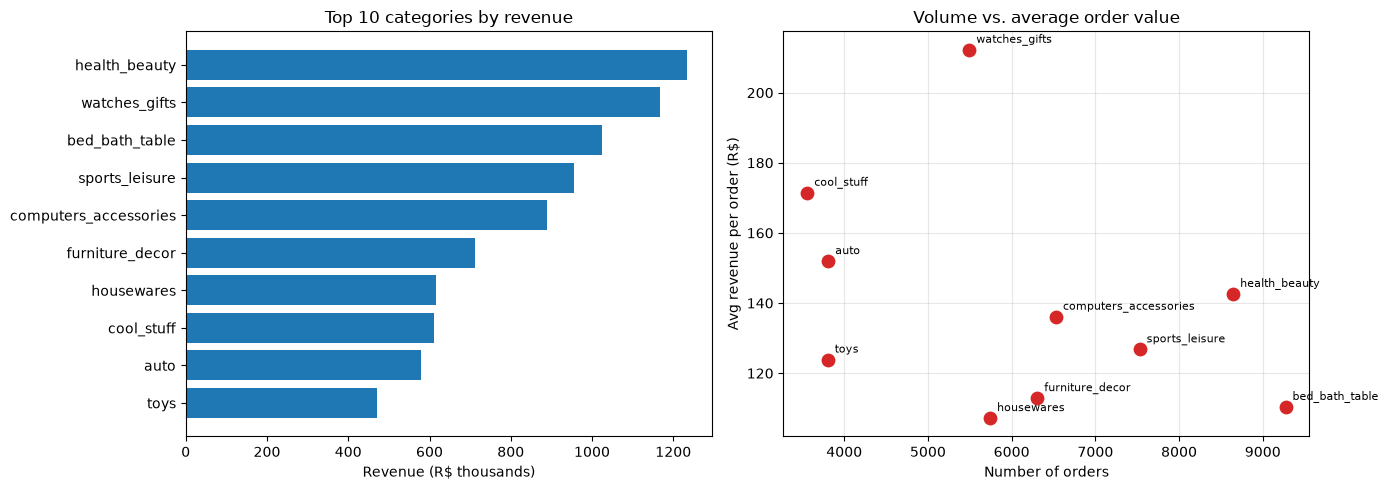

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: revenue by category
cat = q2_cat.sort_values("revenue")
axes[0].barh(cat["category"], cat["revenue"] / 1000, color="#1f77b4")
axes[0].set_title("Top 10 categories by revenue")
axes[0].set_xlabel("Revenue (R$ thousands)")

# Right: volume vs. order value
axes[1].scatter(q2_cat["orders"], q2_cat["avg_revenue_per_order"], s=80, color="#d62728")
for _, r in q2_cat.iterrows():
    axes[1].annotate(r["category"], (r["orders"], r["avg_revenue_per_order"]),
                     xytext=(5, 5), textcoords="offset points", fontsize=8)
axes[1].set_title("Volume vs. average order value")
axes[1].set_xlabel("Number of orders")
axes[1].set_ylabel("Avg revenue per order (R$)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(images / "q2_categories.png", dpi=150)
plt.show()

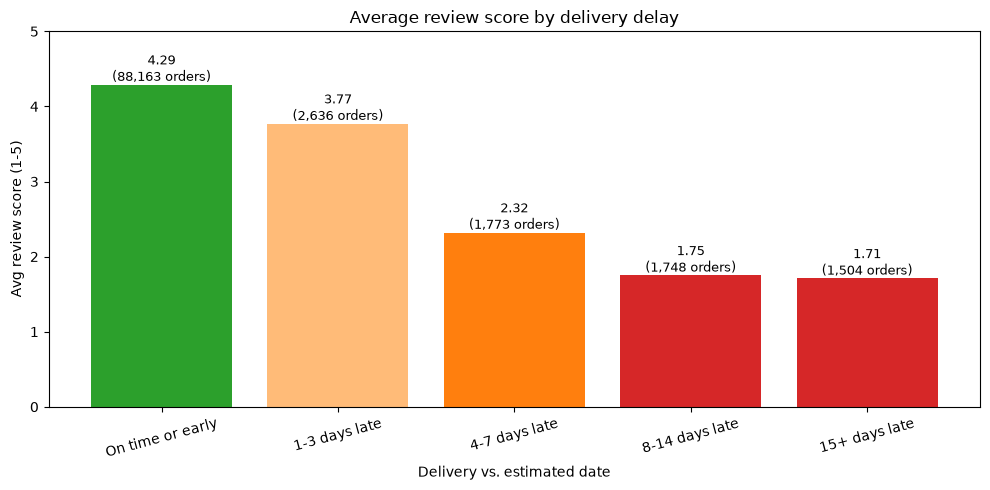

In [8]:
q4_plot = q4.copy()
q4_plot["label"] = q4_plot["delay_bucket"].str[3:]   # drop the "1. " prefix

colors = ["#2ca02c", "#ffbb78", "#ff7f0e", "#d62728", "#d62728"]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(q4_plot["label"], q4_plot["avg_review_score"], color=colors)

for bar, n in zip(bars, q4_plot["orders"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
            f"{bar.get_height():.2f}\n({n:,} orders)",
            ha="center", fontsize=9)

ax.set_ylim(0, 5)
ax.set_title("Average review score by delivery delay")
ax.set_ylabel("Avg review score (1-5)")
ax.set_xlabel("Delivery vs. estimated date")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(images / "q4_delay_vs_reviews.png", dpi=150)
plt.show()

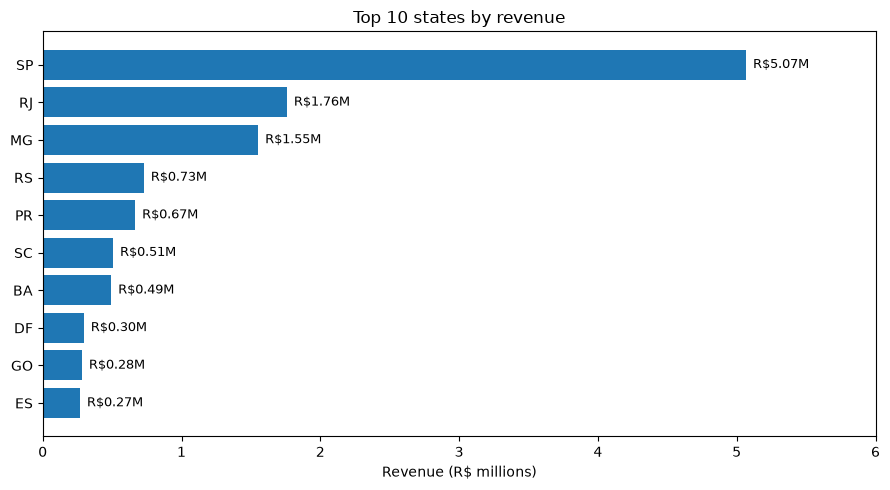

In [9]:
st = q2_state.sort_values("revenue")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(st["state"], st["revenue"] / 1000000, color="#1f77b4")

total_top10 = q2_state["revenue"].sum()
for i, (s, r) in enumerate(zip(st["state"], st["revenue"])):
    ax.text(r / 1000000 + 0.05, i, f"R${r/1e6:.2f}M", va="center", fontsize=9)

ax.set_title("Top 10 states by revenue")
ax.set_xlabel("Revenue (R$ millions)")
ax.set_xlim(0, 6)
plt.tight_layout()
plt.savefig(images / "q2_states.png", dpi=150)
plt.show()

In [10]:
from pathlib import Path

for folder in ["Downloads", "Documents", "Desktop", "olist-project", "OneDrive"]:
    for p in (Path.home() / folder).rglob("order_items_flat*"):
        print(p)

C:\Users\Kramz\Downloads\archive\order_items_flat.csv
